In [1]:

import pandas as pd

df = pd.read_csv('/content/retail_sales_dataset.csv')

print("First 5 rows:")
display(df.head())

print("Dataset Shape:")
print(df.shape)

print("Column Names:")
print(df.columns.tolist())


First 5 rows:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


Dataset Shape:
(1000, 9)
Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


In [2]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Rows:
0

Statistical Summary:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


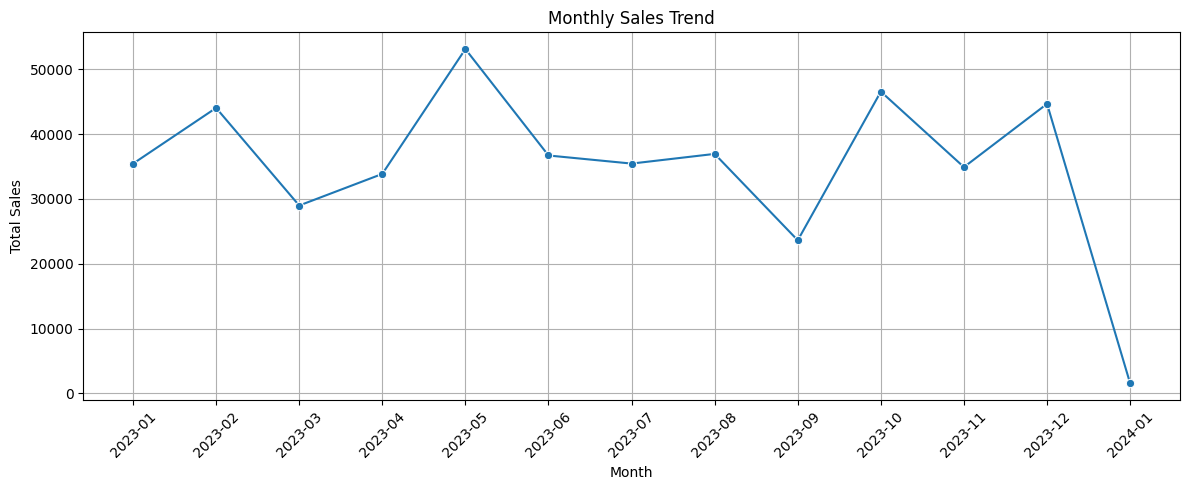

In [3]:

import matplotlib.pyplot as plt
import seaborn as sns

# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Create monthly sales
df['Month'] = df['Date'].dt.to_period('M').astype(str)
monthly_sales = df.groupby('Month')['Total Amount'].sum()

# Plot monthly sales trend
plt.figure(figsize=(12, 5))
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


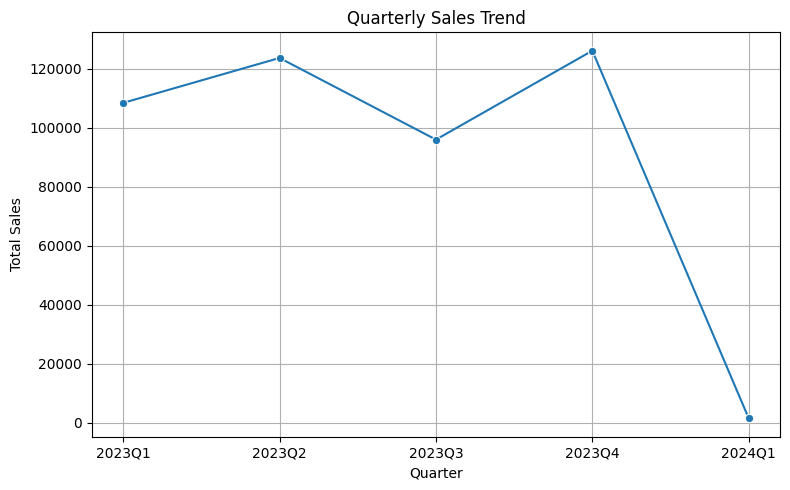

Quarterly Sales:


,Total Amount
Quarter,
2023Q1,108500
2023Q2,123735
2023Q3,96045
2023Q4,126190
2024Q1,1530


In [4]:

# Create quarterly sales
df['Quarter'] = df['Date'].dt.to_period('Q').astype(str)
quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

# Plot quarterly sales trend
plt.figure(figsize=(8, 5))
sns.lineplot(
    x=quarterly_sales.index,
    y=quarterly_sales.values,
    marker='o'
)
plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.grid(True)
plt.tight_layout()
plt.show()

print("Quarterly Sales:")
display(quarterly_sales)


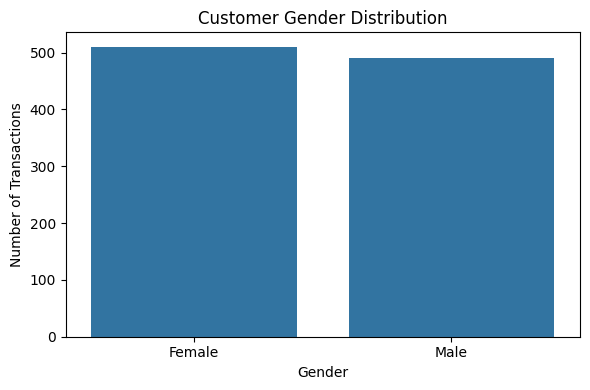

Gender-wise Transaction Count:


,count
Gender,
Female,510
Male,490


In [5]:

# Count transactions by gender
gender_count = df['Gender'].value_counts()

# Plot gender distribution
plt.figure(figsize=(6, 4))
sns.barplot(x=gender_count.index, y=gender_count.values)

plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Transactions')
plt.tight_layout()
plt.show()

print("Gender-wise Transaction Count:")
display(gender_count)


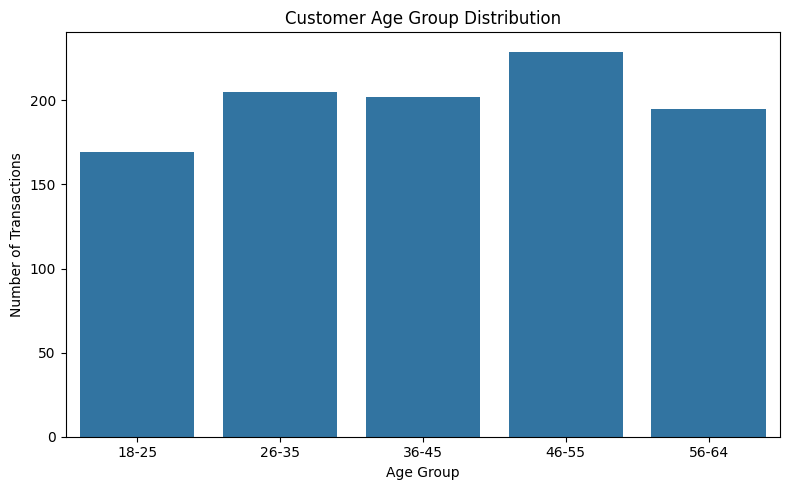

Age Group Transaction Count:


,count
Age Group,
18-25,169
26-35,205
36-45,202
46-55,229
56-64,195


In [6]:

# Create age groups
bins = [17, 25, 35, 45, 55, 65]
labels = ['18-25', '26-35', '36-45', '46-55', '56-64']

df['Age Group'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels
)

# Count transactions in each age group
age_count = df['Age Group'].value_counts().sort_index()

# Plot age group distribution
plt.figure(figsize=(8, 5))
sns.barplot(x=age_count.index, y=age_count.values)

plt.title('Customer Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Number of Transactions')
plt.tight_layout()
plt.show()

print("Age Group Transaction Count:")
display(age_count)


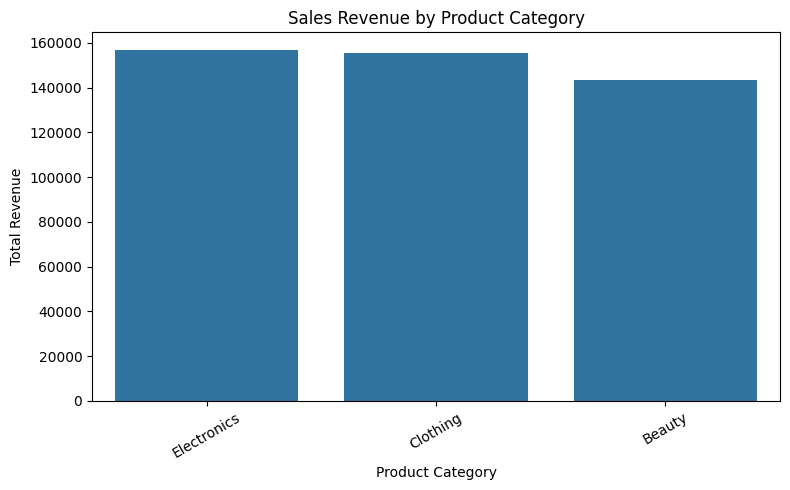

Revenue by Product Category:


,Total Amount
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515


In [7]:

# Calculate sales by product category
category_sales = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)

# Plot category sales
plt.figure(figsize=(8, 5))
sns.barplot(x=category_sales.index, y=category_sales.values)

plt.title('Sales Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Revenue by Product Category:")
display(category_sales)


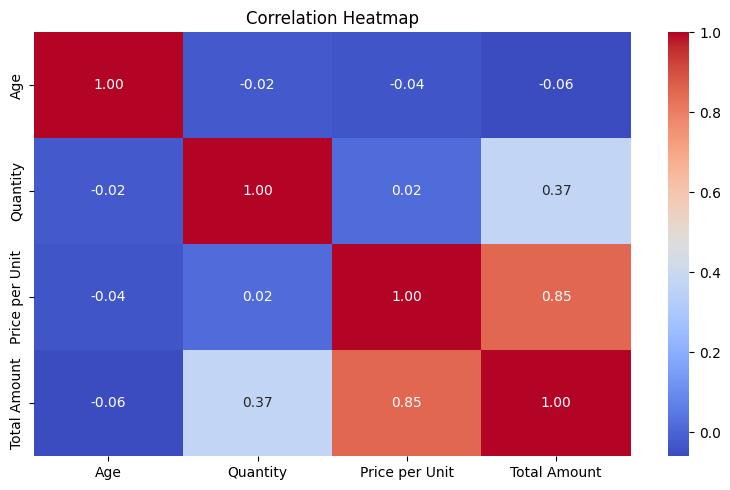

In [8]:

# Select numeric columns
numeric_df = df[
    ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
]

# Calculate correlation
correlation = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


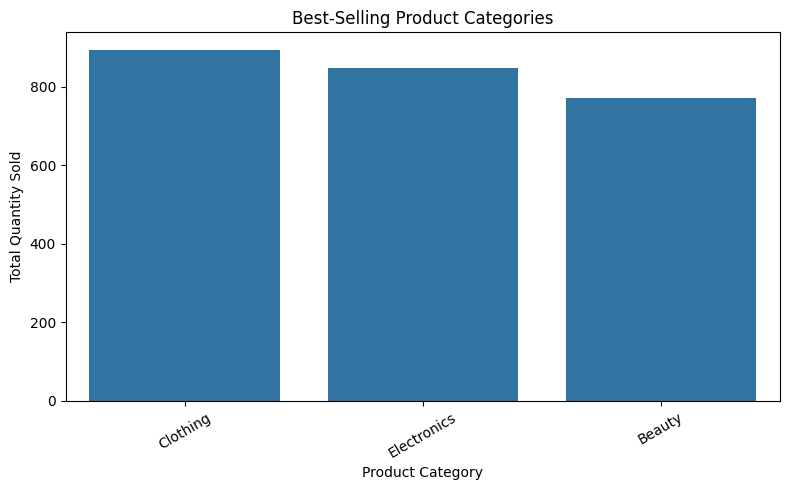

Quantity Sold by Category:


,Quantity
Product Category,
Clothing,894
Electronics,849
Beauty,771


In [9]:

# Calculate quantity sold by category
top_categories = (
    df.groupby('Product Category')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

# Plot quantity sold
plt.figure(figsize=(8, 5))
sns.barplot(x=top_categories.index, y=top_categories.values)

plt.title('Best-Selling Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Quantity Sold by Category:")
display(top_categories)


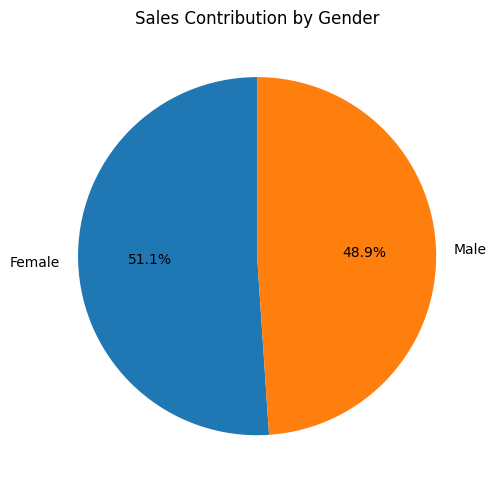

Total Sales by Gender:


,Total Amount
Gender,
Female,232840
Male,223160


In [10]:

# Calculate total sales by gender
gender_sales = df.groupby('Gender')['Total Amount'].sum()

# Plot gender-wise sales
plt.figure(figsize=(7, 5))
plt.pie(
    gender_sales.values,
    labels=gender_sales.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Sales Contribution by Gender')
plt.tight_layout()
plt.show()

print("Total Sales by Gender:")
display(gender_sales)


In [11]:

print("EDA OBSERVATIONS")
print("-----------------")

print("1. Total transactions:", len(df))
print("2. Total revenue:", df['Total Amount'].sum())
print("3. Average transaction amount:", round(df['Total Amount'].mean(), 2))
print("4. Average customer age:", round(df['Age'].mean(), 2))

print("\nHighest Revenue Category:")
print(category_sales.idxmax(), "-", category_sales.max())

print("\nHighest Quantity Category:")
print(top_categories.idxmax(), "-", top_categories.max())

print("\nBUSINESS RECOMMENDATIONS")
print("------------------------")
print("1. Focus marketing on high-revenue product categories.")
print("2. Provide offers based on customer purchasing patterns.")
print("3. Monitor monthly and quarterly sales to plan inventory.")


EDA OBSERVATIONS
-----------------
1. Total transactions: 1000
2. Total revenue: 456000
3. Average transaction amount: 456.0
4. Average customer age: 41.39

Highest Revenue Category:
Electronics - 156905

Highest Quantity Category:
Clothing - 894

BUSINESS RECOMMENDATIONS
------------------------
1. Focus marketing on high-revenue product categories.
2. Provide offers based on customer purchasing patterns.
3. Monitor monthly and quarterly sales to plan inventory.


In [ ]:
## Conclusion

Exploratory Data Analysis (EDA) was performed on the Retail Sales Dataset containing 1,000 transactions and 9 original columns.

The dataset was inspected for missing values, duplicate records, and data types. No missing values or duplicate rows were found. Monthly and quarterly sales trends, customer gender distribution, age groups, product category revenue, and quantity sold were analysed using visualizations. A correlation heatmap was also created to understand relationships between numerical variables.

### Business Recommendations

1. Focus on product categories that generate the highest revenue.
2. Use monthly and quarterly sales trends to plan stock and promotional campaigns.
3. Study customer age groups and gender-wise purchasing patterns to improve marketing strategies.

This analysis helps understand retail sales patterns and supports data-driven business decisions.